# Learned concept swaps across models

**Question.** Can concept directions learned from independent contexts replace an intermediate concept and redirect the final answer? How do mean-difference and fitted linear probes compare with J-token and ordinary logit-token swaps?

**Answer in this committed notebook.** The existing GPT-2 implementations use **mean-difference probe directions**, not a trained logistic/ridge classifier. The Qwen implementation has no learned-probe arm. This notebook adds both the legacy mean-difference method and an actual ridge linear classifier, with a held-out-template check and the same audited causal tasks as the token-swap notebook. The data audit and CPU smoke example have been executed; **pretrained causal effects remain unmeasured**.

Set `RUN_MODEL=True` to run on a pretrained model. Colab clone/pull and dependency setup, the pinned Hugging Face J-lens, cached expensive steps, strict answer scoring, and final-normalization gains follow the token-swap notebook.

## Repository setup (local or Colab)

In a fresh Colab session, clone this GitHub fork; reuse an existing clone with
`git pull --ff-only` and install its dependencies into the active Python environment.
A notebook opened inside a local checkout uses that checkout directly. Clone, pull,
and installation errors stop the setup cell. Run this cell before importing `jlens`;
if you already imported an older version in this session, restart the runtime first.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/ai360-project-school-j-lens/jacobian-lens-gpt2.git"
IN_COLAB = "COLAB_RELEASE_TAG" in os.environ or "google.colab" in sys.modules

# Reuse a checkout when opened locally, including from a nested notebook folder.
local_repo = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "jlens" / "evaluation.py").is_file()),
    None,
)
REPO_DIR = local_repo or Path.cwd() / "jacobian-lens-gpt2"
if local_repo is not None:
    if IN_COLAB:
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
elif REPO_DIR.exists():
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

ROOT = REPO_DIR.resolve()
if IN_COLAB:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True,
    )
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
if not (ROOT / "jlens" / "concept_probes.py").is_file():
    raise RuntimeError("Update this checkout to the revision containing jlens/concept_probes.py.")
print(f"Repository ready: {ROOT.name}")

Repository ready: jacobian-lens-gpt2


In [2]:
import json

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

from jlens.concept_probes import (
    audit_probe_templates,
    collect_probe_features,
    fit_concept_probes,
    prepare_probe_examples,
    probe_directions,
    probe_fingerprint,
)
from jlens.swap_experiment import (
    experiment_fingerprint,
    intermediate_bands,
    load_swap_trials,
    prepare_swap_trials,
    run_swap_experiment,
)

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", 20)
RUN_MODEL = os.environ.get("JLENS_RUN_MODEL", "0") == "1"  # Set True for pretrained inference.
MODEL_ID = os.environ.get("JLENS_MODEL_ID", "Qwen/Qwen3-4B")
MODEL_REVISION = os.environ.get("JLENS_MODEL_REVISION", "main")  # Pin a commit for repeat runs.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float32
EXISTING_LENS_PATH = os.environ.get("JLENS_LENS_PATH")  # Matching FINAL lens; never a checkpoint.
# Published J-lens files checked at the pinned Neuronpedia revision below.
HUB_LENS_FILES = {
    "Qwen/Qwen3-4B": "qwen3-4b/jlens/Salesforce-wikitext/Qwen3-4B_jacobian_lens.pt",
    "Qwen/Qwen3-1.7B": "qwen3-1.7b/jlens/Salesforce-wikitext/Qwen3-1.7B_jacobian_lens.pt",
    "openai-community/gpt2": "gpt2-small/jlens/Salesforce-wikitext/gpt2_jacobian_lens.pt",
    "google/gemma-4-31B": "gemma-4-31b/jlens/Salesforce-wikitext/gemma-4-31B_jacobian_lens.pt",
    "Qwen/Qwen3.5-9B-Base": "qwen3.5-9b-pt/jlens/Salesforce-wikitext/Qwen3.5-9B-Base_jacobian_lens.pt",
    "Qwen/Qwen3.5-4B": "qwen3.5-4b/jlens/Salesforce-wikitext/Qwen3.5-4B_jacobian_lens_n1000.pt",
}
HUB_LENS = (
    dict(repo_id="neuronpedia/jacobian-lens", filename=HUB_LENS_FILES[MODEL_ID],
         revision="9fa267f841d62aa468dab5b9b38c3dc45a82d863")
    if MODEL_ID in HUB_LENS_FILES and not EXISTING_LENS_PATH else None
)
# For another model, supply its exact artifact: dict(repo_id=..., filename=..., revision=...).
FIT_LENS = False  # Set True and HUB_LENS=None only to deliberately run/load a managed fit.
LENS_PROVENANCE = None
lens = None
BATCH_SIZE = 16
ALPHAS = [0.0, 1.0, 2.0]
SEED = 0
MAX_PROMPT_LENGTH = 256
RUN_ROOT = ROOT / "runs/model-agnostic-concept-swap"
PROBE_BATCH_SIZE = 32
PROBE_MAX_LENGTH = 128
HELD_OUT_TEMPLATES = 5
RIDGE = 0.1  # Fixed in advance; do not select using swap success or held-out accuracy.
results = prepared = fitted_probes = learned_directions = None
print(f"Pretrained experiment enabled: {RUN_MODEL}; device: {DEVICE}")

Pretrained experiment enabled: False; device: cpu


## What the existing implementation actually does

The GPT-2 notebooks (`gpt2-xl/jacobian_lens/concept_swap.ipynb` and `gpt2-xl/latent_bridge_v2/latent_bridge_v2_swap.ipynb`) take residual activations at the explicitly named concept token in 20 neutral templates. Their `probe` vector is

`w_c = mean_templates h(c) − mean_all_concepts mean_templates h(c')`.

This is a **linear mean-difference probe direction**. It does not optimize a classifier loss, and the old notebooks do not evaluate it on held-out templates. The Qwen3-4B notebook runs only J-token, logit-token, and random directions. It also records concept single-token flags without enforcing them in its trial filter. Here, token-vector comparisons strictly enforce complete single tokens.

The [paper's probe experiment](https://transformer-circuits.pub/2026/workspace/index.html) constructs mean-difference probes from prompts that **imply** an intermediate, then separates their sparse J-space components and remainders. The local explicit-name templates are a different training distribution. This notebook compares full learned directions to token directions; it does not claim to reproduce that sparse decomposition experiment.

In [3]:
probe_audit = json.loads((ROOT / "data/experiments/concept-swap-audit.json").read_text())
display(pd.DataFrame(probe_audit["existing_implementations"]))
for finding in probe_audit["findings"]:
    print("•", finding)

,notebook,representation,trained_classifier,held_out_template_check
0,notebooks/gpt2-xl/jacobian_lens/concept_swap.ipynb,"Mean residual at the explicitly named concept token across 20 templates, minus the mean across c...",False,False
1,notebooks/gpt2-xl/latent_bridge_v2/latent_bridge_v2_swap.ipynb,Same mean-difference probe; task subjects preselected for GPT-2 XL.,False,False
2,notebooks/qwen3-4b/jacobian_lens_prefitted/concept_swap.ipynb,"J-token, logit-token and random directions; no learned-probe arm.",False,False


• All 20 templates explicitly name the concept; they are lexical contexts, not evidence that the concept is represented implicitly.
• Only the causal prefix through the concept can affect its activation. Suffix-only template variants must not cross train/test splits.
• The local templates are reusable training contexts, not Anthropic's implied-intermediate probe training prompts.
• No exact template-filled prompt overlaps the task prompts. This lexical non-overlap is weaker than semantic independence.
• Task answers and swap outcomes are not probe-training labels. Classes are concept names.
• The Qwen notebook records single-token flags but its correct_trials filter does not enforce them; first-token concept fallbacks can enter its swaps.
• The legacy claim that vector scale does not matter is too broad: a common scale cancels, but different source and target rescalings change the swap.


## Dataset provenance and quality

The local `probe-swap.json` and `flexible-generalization.json` were verified **byte-for-byte** against [Anthropic's upstream release at commit 581d398](https://github.com/anthropics/jacobian-lens/tree/581d398613e5602a5af361e1c34d3a92ea82ba8e/data/experiments). Their hashes and the review decisions are in `data/experiments/token-swap-audit.json`; the original data are unchanged. The [paper](https://transformer-circuits.pub/2026/workspace/index.html) motivates bandwise coordinate interventions; this notebook is an adaptation, not an exact replication of its model or scores.

The review found incomplete answer labels (e.g. `North`, `Canadian`, `Civil`, and square answers `twenty`/`forty`/`eighty`), underspecified relations, and counterfactuals that violate the question's answer type. The China population premise is outdated: see [UN DESA's 2023 population brief](https://www.un.org/development/desa/pd/content/policy-brief153). Exclusions are conservative review decisions, not an exhaustive certification that every retained fact and alternative wording is correct.

Local v1 has 400 trials from **100 landmark prompts**, each with four replacement countries. It is useful as a narrow supplementary country→language task, with repeated prompts and simplified language labels. Remove ambiguous transboundary/disputed landmarks and India language trials conservatively. V2 has 1,416 trials from 354 subjects selected on GPT-2 XL answers; its 100% construction baseline does not transfer to other models. The default uses v1 instead. Explicit-source flexible tasks and latent-source two-hop tasks must not be pooled.

In [4]:
audit = json.loads((ROOT / "data/experiments/token-swap-audit.json").read_text())
trials = load_swap_trials(ROOT)
quality_summary = trials.groupby("dataset").agg(
    raw_trials=("name", "size"), raw_prompts=("prompt", "nunique"),
    retained_trials=("quality_ok", "sum"),
)
quality_summary["retained_prompts"] = trials[trials.quality_ok].groupby("dataset").prompt.nunique()
display(quality_summary)
display(trials[~trials.quality_ok].groupby(["dataset", "quality_reason"]).size().rename("excluded_trials").to_frame())
print(audit["latent_v2"])
for limitation in audit["limitations"]:
    print("•", limitation)

,raw_trials,raw_prompts,retained_trials,retained_prompts
dataset,,,,
flexible-generalization,192,64,144,48
latent-bridge,400,100,344,91
probe-swap,90,86,71,68


excluded_trials
dataset                 quality_reason                                                                                                       
flexible-generalization Biggest holiday is culture-dependent, Easter moves, and labels are fragments.                                      12
                        North is an incomplete answer for North America; exclude the whole relation for balanced coverage.                 12
                        Sky/outdoors do not specify a unique natural habitat.                                                              12
                        twenty, forty and eighty are only prefixes of 25, 49 and 81.                                                       12
latent-bridge           Country attribution in East Jerusalem is disputed.                                                                  8
                        One canonical main-language label hides substantial linguistic diversity; excluded conservatively.                 40
                        Transboundary landmark does not identify a unique country.                                                          4
                        Transboundary landmark does not identify a unique country.; One canonical main-language label hid...                4
probe-swap              At least one label is only a prefix of a multi-word answer.                                                         7
                        Belgium has more than one western neighbor; direction is underspecified.                                            1
                        Colors depend on species; the eagle label is underspecified.                                                        1
                        Easter does not have a fixed month.                                                                                 1
                        Lung lobes are not heart chambers; the counterfactual changes relation.                                             1
                        Outdated China premise; India overtook China in 2023.                                                               1
                        Seasons require a hemisphere; none is specified.                                                                    1
                        The counterfactual asks for a fruit, but barley is a cereal.                                                        1
                        The counterfactual asks for an animal but labels earth.                                                             1
                        The counterfactual asks for an insect but labels a cow.                                                             1
                        The counterfactual rider's power source is ill-formed for a train.                                                  1
                        The swan-to-England national-emblem relation is not well defined.                                                   1
                        Wooden objects used to strike an instrument do not describe piano keys.                                             1

Excluded from default experiments: 1416 rows are four targets for 354 subjects preselected for GPT-2 XL capability. Use v1 for cross-model coverage; v2 requires a separately reported model-specific analysis.
• Latent bridge v1 has one country-to-language relation, 100 source landmarks and four targets per prompt, not 400 independent questions.
• Country/language labels simplify multilingual countries; retained labels are canonical continuations, not exhaustive accepted answers.
• Single-token scoring undercounts valid synonyms, number forms and multi-token answers; report coverage for each tokenizer.
• Anthropic flexible tasks explicitly mention the source; report separately from hidden intermediate tasks.
• Do not select the best band on the same prompts and call its score held-out performance.


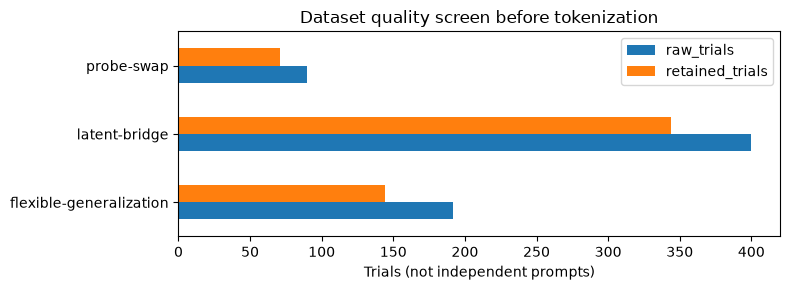

In [5]:
fig, ax = plt.subplots(figsize=(8, 3))
quality_summary[["raw_trials", "retained_trials"]].plot.barh(ax=ax)
ax.set(xlabel="Trials (not independent prompts)", ylabel="", title="Dataset quality screen before tokenization")
plt.tight_layout()
plt.show()

## Probe data audit and split

The 20 existing templates have one `{x}` slot and distinct causal prefixes. Keep them as a **lexical baseline**, rather than treating them as validated examples of latent semantic representations. They contain no task-specific answer labels. Fill every retained concept into every template and use a fixed split of 15 training versus 5 held-out templates. Reject duplicate prefixes (suffix changes are causally invisible at the mention), malformed placeholders, unsupported token offsets, incomplete mentions, unknown tokens, and over-length inputs.

Read the last token of the **complete concept mention**, using character offsets checked against the adapter's actual encoded IDs. This handles multi-token concepts and BOS automatically, without prefix-length guesses. Tokenizers without offset mapping are reported as unsupported, not silently approximated. Retain a concept only if all 20 contexts are valid, preserving equal class coverage. Fit both methods on the same 15 training contexts; never fit on held-out contexts or task prompts. Unlike the older all-20-template calculation, this leaves an independent template diagnostic.

Concept vocabulary selection uses audited source/target labels, not model correctness or intervention outcomes. The vocabulary affects the grand mean and negative classes, so its exact order and per-model exclusions are cached.

In [6]:
templates = json.loads((ROOT / "data/experiments/concept-probe-templates.json").read_text())["templates"]
template_audit = audit_probe_templates(templates, seed=SEED, held_out=HELD_OUT_TEMPLATES)
CONCEPTS = sorted(set(trials.loc[trials.quality_ok, "source"]) | set(trials.loc[trials.quality_ok, "target"]))
filled = {template.format(x=concept).strip() for template in templates for concept in CONCEPTS}
overlap = filled & set(trials.prompt.str.strip())
assert not overlap, f"Probe training/task prompt overlap: {overlap}"
display(template_audit[["template_id", "template", "split"]])
display(pd.DataFrame([{
    "concepts_before_tokenizer_audit": len(CONCEPTS),
    "templates": len(templates), "distinct_causal_prefixes": template_audit.prefix.nunique(),
    "training_contexts": len(CONCEPTS) * sum(template_audit.split.eq("train")),
    "held_out_contexts": len(CONCEPTS) * sum(template_audit.split.eq("test")),
    "exact_task_prompt_overlap": len(overlap),
}]))

,template_id,template,split
0,0,Let me tell you about {x}.,train
1,1,Today we will talk about {x}.,train
2,2,The next topic is {x}.,train
3,3,Here are some facts about {x}:,train
4,4,I have been thinking about {x} a lot.,test
5,5,This article is about {x}.,test
6,6,Keyword: {x}.,train
7,7,My favorite thing to read about is {x}.,test
8,8,Question: what do you know about {x}?,train
9,9,She wrote a long essay on {x}.,train


,concepts_before_tokenizer_audit,templates,distinct_causal_prefixes,training_contexts,held_out_contexts,exact_task_prompt_overlap
0,98,20,20,1470,490,0


## Probe fitting, controls, and interpretation

**Mean difference (`probe_mean`).** Preserve the legacy `μ_c − mean_c μ_c` directions, using training templates only. The diagnostic uses the corresponding nearest-centroid linear score, with its bias.

**Ridge classifier (`probe_ridge`).** Regress one-hot concept labels on residual activations with a learned intercept and fixed L2 penalty. Training features are centered and rescaled by one global RMS scalar; fitted coefficients are converted back into residual coordinates before interventions. The solver uses the smaller primal/dual system. The loss is `mean(||XW + b − Y||²) + RIDGE × ||W||²` in scaled coordinates. Biases are used for classification diagnostics, not added to hidden states. No held-out label or swap outcome chooses `RIDGE`.

Probe weights already live in residual space: **do not multiply them by the final norm gain or J again**. For the token controls, the gain is retained: `U diag(gain) C J` for LayerNorm, `U diag(gain) J` for RMSNorm, and omit J for the logit arm.

Use identical clean-coordinate clamping for every direction pair: `h ← h + V[c_clean + α(swap(c_clean) − c_clean) − V⁺h]`. At α=1 the two clean coordinates exchange; α=0 is an exact no-op. Preserve direction norms: only a common scaling of both vectors cancels. A learned classifier is a readout, so using its weights as write directions is an empirical intervention, not a guarantee of concept transfer.

The matched cohort has J, logit, mean-probe, ridge-probe, and three random controls (one each matched to J, mean, and ridge updates). Additional multi-token concepts are a separate probe-only cohort with two matched random controls. Every control replays its own reference arm's actual update norm at every position and layer. No token fragments stand in for missing J-token vectors. Degenerate pairs fail visibly instead of silently using an underdetermined swap.

All prompt passes are batched. Patch only real, non-special positions. Read final model logits at each row's last real token. Report raw coverage, correct-baseline counts, targeted flips, any output change, and target-probability gain, separately by dataset/cohort. Macro-average targets within prompt before averaging across prompts. The primary setting is α=1 in the middle band; the rest of the grid is exploratory, without selecting its maximum as held-out performance.

## Executed CPU smoke check

A tiny untrained decoder and a local tokenizer exercise multi-token mention extraction, batched probe fitting, and learned-direction swaps. These outputs validate mechanics only; they are **not pretrained model results**. Real model artifacts and results are cached in the sections below.

In [7]:
from tokenizers import Tokenizer
from tokenizers.models import WordLevel
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.processors import TemplateProcessing
from transformers import PreTrainedTokenizerFast

from jlens import JacobianLens
from tests.tiny import TinyDecoder

smoke_words = ["[UNK]", "[BOS]", "[PAD]", "Topic", ":", "Read", "about", "today", ".",
               "Write", "a", "note", "Subject", "!", "red", "fox", "blue", "whale", "green", "bird"]
backend = Tokenizer(WordLevel({word: i for i, word in enumerate(smoke_words)}, unk_token="[UNK]"))
backend.pre_tokenizer = Whitespace()
backend.post_processor = TemplateProcessing(single="[BOS] $A", special_tokens=[("[BOS]", 1)])
smoke_tokenizer = PreTrainedTokenizerFast(tokenizer_object=backend, unk_token="[UNK]", bos_token="[BOS]", pad_token="[PAD]")
smoke_model = TinyDecoder().eval()
smoke_model.tokenizer = smoke_tokenizer
smoke_model.encode_ids = lambda text, max_length: smoke_tokenizer(text, truncation=True, max_length=max_length)["input_ids"]
smoke_templates = audit_probe_templates(
    ["Topic: {x}.", "Read about {x} today.", "Write a note about {x}.", "Subject: {x}!"], held_out=1,
)
smoke_examples = prepare_probe_examples(smoke_model, ["red fox", "blue whale", "green bird"], smoke_templates)
assert smoke_examples.valid.all() and smoke_examples.concept_tokens.eq(2).all()
smoke_features = collect_probe_features(smoke_model, smoke_examples, [1, 2], batch_size=8, progress=False)
smoke_fit = fit_concept_probes(smoke_features, smoke_examples, ridge=RIDGE)
display(pd.DataFrame(smoke_fit["diagnostics"]))
smoke_trials = pd.DataFrame([
    dict(trial_id=str(i), dataset="synthetic", group="smoke", name=str(i),
         prompt=prompt, source=source, target=target, answer="fox", swap_answer="whale",
         input_ids=smoke_model.encode_ids(prompt, 128), source_id=None, target_id=None,
         answer_ids=[15], swap_answer_ids=[17], eligible=True)
    for i, (prompt, source, target) in enumerate([
        ("Topic: red fox.", "red fox", "blue whale"),
        ("Write a note about green bird.", "green bird", "blue whale"),
    ])
])
smoke_lens = JacobianLens({layer: torch.eye(smoke_model.d_model) for layer in [1, 2]}, n_prompts=1, d_model=smoke_model.d_model)
smoke_results = run_swap_experiment(
    smoke_model, smoke_lens, smoke_trials, bands={"middle": [1, 2]}, alphas=[0, 1],
    batch_size=8, token_controls=False, concept_directions=probe_directions(smoke_fit), progress=False,
)
assert not smoke_results[smoke_results.alpha.eq(0)].changed.any()
display(smoke_results.groupby(["mode", "alpha"]).agg(trials=("name", "size"), changes=("changed", "sum")))
print("CPU check passed; no-op swaps preserve the output. Pretrained causal effects remain unmeasured.")

,layer,method,train_accuracy,test_accuracy,chance,train_examples,test_examples
0,1,probe_mean,1.0,1.0,0.333333,9,3
1,1,probe_ridge,1.0,1.0,0.333333,9,3
2,2,probe_mean,1.0,1.0,0.333333,9,3
3,2,probe_ridge,1.0,1.0,0.333333,9,3


trials  changes
mode               alpha                 
probe_mean         0           2        0
                   1           2        2
probe_ridge        0           2        0
                   1           2        2
random_probe_mean  0           2        0
                   1           2        2
random_probe_ridge 0           2        0
                   1           2        2

CPU check passed; no-op swaps preserve the output. Pretrained causal effects remain unmeasured.


## Load a model and a matching lens

Enable `RUN_MODEL` in the configuration cell. Change `MODEL_ID` and optionally `MODEL_REVISION`; the same evaluator handles any supported `from_hf` layout. Models must be in evaluation mode. This notebook uses one device and fp32 by default; large models need sufficient memory or an explicitly chosen supported dtype. No architecture-specific layer path is used here.

**Default: download the pretrained J-lens from [neuronpedia/jacobian-lens](https://huggingface.co/neuronpedia/jacobian-lens/tree/9fa267f841d62aa468dab5b9b38c3dc45a82d863).** `MODEL_ID` defaults to Qwen3-4B, matching the original pretrained swap notebook. `HUB_LENS` selects its exact file and pins a Hub commit; the preset table also covers several other models. For another published model, supply `HUB_LENS = dict(repo_id=..., filename=..., revision=...)` explicitly. The old Qwen3-0.6B default has no J-lens file in this pinned repository snapshot.

`download_lens_artifact(**HUB_LENS)` downloads the selected file or reuses the Hub cache, checks its published SHA-256 and size, and passes that exact path to the existing lens loader. Width and layer coverage are checked against the selected model. The receipt is displayed and saved with the results; artifact verification does not establish the legacy lens's fitting provenance. A missing/failed Hub download stops and never triggers fitting.

Alternatively, set `HUB_LENS=None` and `EXISTING_LENS_PATH` to a matching local final lens. To deliberately load or create a managed fit, set both sources to `None` and `FIT_LENS=True`. The managed fit records model/runtime, dtype, corpus mix, sequence length, dimension batch size, and exact ordered texts, with resumable checkpoints. No swap prompts are used to fit J. The displayed fitting configuration applies only to this managed-fit option, not to downloaded artifacts.

Run caches live under ignored `runs/`. The result key covers runtime, resolved model revision, tokenizer vocabulary, exact tokenized trials, bands, strengths, batching, seed, implementation, and actual lens matrices. A completed result file skips all expensive clean/patched passes on rerun; interrupted result sweeps restart, while fitting supports checkpoint resume. Local modified model weights need a new explicit run label.

In [8]:
lens = None  # A failed load must not leave an earlier lens available.
results = prepared = fitted_probes = learned_directions = None
LENS_PROVENANCE = None
if RUN_MODEL:
    if sum([HUB_LENS is not None, bool(EXISTING_LENS_PATH), FIT_LENS]) != 1:
        raise ValueError("Choose one lens source: HUB_LENS, EXISTING_LENS_PATH, or FIT_LENS=True.")
    import hashlib

    import transformers
    from transformers import AutoModelForCausalLM, AutoTokenizer

    import jlens
    from jlens.artifact_provenance import download_lens_artifact
    from jlens.evaluation import FIT_MIX, fit_with_progress, load_fit_prompts
    from jlens.notebook_setup import DatasetFitRun, runtime_metadata
    from jlens.sharded_fitting import benchmark_dim_batches

    torch.manual_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
    hf_model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, dtype=DTYPE,
    ).to(DEVICE).eval()
    model = jlens.from_hf(hf_model, tokenizer, compile=False)
    RUNTIME = runtime_metadata(model, hf_model, MODEL_ID, DTYPE, DEVICE)
    FIT_CONFIG = {
        **RUNTIME,
        "max_seq_len": 128, "skip_first": 16,
        "fit_mix": {key: max(1, round(count * 0.25)) for key, count in FIT_MIX.items()},
        "seed": SEED, "run_label": "concept-swap-v1", "checkpoint_every": 5,
        "dim_batch_requested": 8, "candidates": [4, 8, 16, 32],
        "headroom_fraction": 0.15, "headroom_GiB": 2.0,
    }
    fit_run = DatasetFitRun(RUN_ROOT / "fits", FIT_CONFIG)
    selected_path = EXISTING_LENS_PATH
    if HUB_LENS is not None:
        artifact = download_lens_artifact(**HUB_LENS)
        selected_path = artifact.path
        LENS_PROVENANCE = {**artifact.to_dict(), "evaluation_runtime": RUNTIME}
        display(LENS_PROVENANCE)
    lens = fit_run.load_or_fit(
        model, FIT_CONFIG, load_prompts=load_fit_prompts,
        fit=fit_with_progress, benchmark=benchmark_dim_batches,
        display=display, existing_path=selected_path,
    )
    LENS_PATH = str(selected_path or fit_run.lens_path)
    LENS_SOURCE = "hub" if HUB_LENS is not None else "local" if selected_path else "managed"
    BANDS = intermediate_bands(model.n_layers)
    PRIMARY_BAND = list(BANDS)[len(BANDS) // 2]
    PROBE_LAYERS = sorted({layer for band in BANDS.values() for layer in band})
    print("Primary band:", PRIMARY_BAND, "; all bands:", BANDS)

else:
    print("Pretrained model/lens loading skipped. Enable RUN_MODEL to measure causal success.")

Pretrained model/lens loading skipped. Enable RUN_MODEL to measure causal success.


## Encode probe contexts and cache batched activations

The feature cache contains only mention-end activations. Its key covers model/runtime, resolved model revision, tokenizer vocabulary, exact prompts and token spans, train/test split, selected layers, batching, and implementation. Features stay on CPU between stages; fitting processes one layer at a time on the selected device. A completed cache skips probe forwards. Large models still need memory for the model, J matrices, and current batch's block activations.

The exact examples and coverage report remain readable beside cached tensors. Hashes identify files/configuration, not the scientific quality of a downloaded lens. If local model weights are edited, change the run label.

In [9]:
if RUN_MODEL:
    probe_examples = prepare_probe_examples(model, CONCEPTS, template_audit, max_length=PROBE_MAX_LENGTH)
    concept_coverage = probe_examples.groupby("concept").agg(valid_contexts=("valid", "sum"), contexts=("valid", "size"))
    covered_concepts = concept_coverage.index[concept_coverage.valid_contexts.eq(concept_coverage.contexts)].tolist()
    display(concept_coverage)
    display(probe_examples[~probe_examples.valid][["concept", "template_id", "reason"]])
    probe_examples = probe_examples[probe_examples.concept.isin(covered_concepts)].reset_index(drop=True)
    if len(covered_concepts) < 3:
        raise ValueError("Need at least three fully covered concepts; inspect the tokenizer/span exclusions.")
    PROBE_RUNTIME = {
        **RUNTIME, "model_revision_requested": MODEL_REVISION,
        "model_revision_resolved": getattr(hf_model.config, "_commit_hash", None),
        "tokenizer_sha256": hashlib.sha256(json.dumps(tokenizer.get_vocab(), sort_keys=True).encode()).hexdigest(),
        "torch_version": torch.__version__, "transformers_version": transformers.__version__,
        "batch_size": PROBE_BATCH_SIZE, "max_length": PROBE_MAX_LENGTH,
        "seed": SEED, "run_label": "concept-swap-v1",
    }
    feature_key = probe_fingerprint(PROBE_RUNTIME, probe_examples, PROBE_LAYERS)
    probe_dir = RUN_ROOT / "probes" / feature_key
    probe_dir.mkdir(parents=True, exist_ok=True)
    probe_examples.to_json(probe_dir / "examples.json", orient="records", indent=2)
    concept_coverage.to_csv(probe_dir / "coverage.csv")
    (probe_dir / "manifest.json").write_text(json.dumps(PROBE_RUNTIME, indent=2))
    feature_path = probe_dir / "features.pt"
    if feature_path.exists():
        features = torch.load(feature_path, map_location="cpu", weights_only=True)
        print("Loaded cached probe activations:", feature_path)
    else:
        features = collect_probe_features(model, probe_examples, PROBE_LAYERS, batch_size=PROBE_BATCH_SIZE)
        temporary = feature_path.with_suffix(".tmp.pt")
        torch.save(features, temporary)
        temporary.replace(feature_path)
else:
    print("Pretrained probe extraction is disabled.")

Pretrained probe extraction is disabled.


## Fit probes and assess held-out templates

The five held-out templates never contribute to weights, centering, normalization, or regularization choice. The class vocabulary and train/test masks are fixed before fitting. Both classifiers have the same context coverage. A high held-out score can still reflect recognition of the named token; it is not proof that the direction captures an unspoken intermediate. The causal swap tasks below test that transfer separately.

In [10]:
probe_metrics = None
if RUN_MODEL:
    fit_key = probe_fingerprint({**PROBE_RUNTIME, "ridge": RIDGE}, probe_examples, PROBE_LAYERS)
    probe_path = probe_dir / f"fitted_{fit_key}.pt"
    if probe_path.exists():
        fitted_probes = torch.load(probe_path, map_location="cpu", weights_only=True)
        print("Loaded cached fitted probes:", probe_path)
    else:
        fitted_probes = fit_concept_probes(features, probe_examples, ridge=RIDGE, device=DEVICE)
        temporary = probe_path.with_suffix(".tmp.pt")
        torch.save(fitted_probes, temporary)
        temporary.replace(probe_path)
    learned_directions = probe_directions(fitted_probes)
    probe_metrics = pd.DataFrame(fitted_probes["diagnostics"])
    probe_metrics.to_csv(probe_dir / f"diagnostics_{fit_key}.csv", index=False)
    display(probe_metrics)
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for method, frame in probe_metrics.groupby("method"):
        ax.plot(frame.layer, frame.test_accuracy, marker=".", label=f"{method}: held-out template")
    ax.axhline(probe_metrics.chance.iloc[0], color="gray", linestyle="--", label="chance")
    ax.set(xlabel="Block output layer", ylabel="Concept classification accuracy", ylim=(0, 1.02))
    ax.legend()
    plt.tight_layout()
    plt.show()
    del features
else:
    print("No pretrained probe accuracy has been measured.")

No pretrained probe accuracy has been measured.


## Prepare matched and additional concept cohorts

The primary comparison runs all arms on the exact same single-token source/target trials. Extra eligible concepts that lack complete single-token directions are evaluated only through learned probes in a separate cohort. Both cohorts require full single-token answers with disjoint spelling sets. Never compare their aggregate rates as if they were the same task distribution.

In [11]:
cohorts = {}
if RUN_MODEL:
    prepared = prepare_swap_trials(model, trials, max_length=MAX_PROMPT_LENGTH)
    probe_prepared = prepare_swap_trials(model, trials, max_length=MAX_PROMPT_LENGTH, require_single_token_concepts=False)
    has_probe = probe_prepared.source.isin(fitted_probes["concepts"]) & probe_prepared.target.isin(fitted_probes["concepts"])
    matched = prepared.copy()
    matched["eligible"] = matched.eligible & has_probe
    additional = probe_prepared.copy()
    # Keep this cohort disjoint from the token-comparable cohort.
    additional["eligible"] = additional.eligible & has_probe & ~prepared.eligible
    cohorts = {"matched_single_token": (matched, True), "additional_concepts": (additional, False)}
    coverage = []
    for cohort, (frame, _token_controls) in cohorts.items():
        frame.to_json(probe_dir / f"{cohort}_trial_audit.json", orient="records", indent=2)
        for dataset, group in frame.groupby("dataset"):
            coverage.append(dict(cohort=cohort, dataset=dataset, raw_trials=len(group),
                                 eligible_trials=int(group.eligible.sum()),
                                 eligible_prompts=group.loc[group.eligible, "prompt"].nunique()))
    display(pd.DataFrame(coverage))
    display(prepared[~prepared.token_ok].groupby(["dataset", "token_reason"]).size().rename("trials").to_frame())
else:
    print("Cohort coverage depends on the selected model's tokenizer; not measured yet.")

Cohort coverage depends on the selected model's tokenizer; not measured yet.


## Run and cache causal swaps

The result key additionally hashes actual learned directions, J matrices, exact task tokenization, strengths, bands, seed, and evaluator code. A completed result cache skips all clean/patched forwards for that cohort. Model loading is still needed to validate identities and encoding. Random draws depend on batching, which is part of the key. All eligible trials are retained in the files; headline success is conditional on a unique correct baseline answer.

In [12]:
results = None
if RUN_MODEL:
    if lens is None or learned_directions is None:
        raise RuntimeError("Load the J-lens and fit/load concept probes before swapping.")
    pieces = []
    for cohort, (frame, token_controls) in cohorts.items():
        if not frame.eligible.any():
            print(cohort, ": no eligible trials")
            continue
        metadata = {
            **PROBE_RUNTIME, "probe_fit_key": fit_key, "ridge": RIDGE,
            "lens_source": LENS_SOURCE, "lens_origin": LENS_PATH, "lens_artifact": LENS_PROVENANCE,
            "lens_n_prompts": lens.n_prompts, "cohort": cohort, "token_controls": token_controls,
            "bands": BANDS, "alphas": ALPHAS, "batch_size": BATCH_SIZE, "seed": SEED,
        }
        key = experiment_fingerprint(metadata, frame, lens, concept_directions=learned_directions)
        run_dir = RUN_ROOT / "swaps" / key
        run_dir.mkdir(parents=True, exist_ok=True)
        (run_dir / "manifest.json").write_text(json.dumps(metadata, indent=2))
        if LENS_PROVENANCE is not None:
            (run_dir / "downloaded_lens_provenance.json").write_text(json.dumps(LENS_PROVENANCE, indent=2))
        result_path = run_dir / "results.json"
        if result_path.exists():
            result = pd.DataFrame(json.loads(result_path.read_text()))
            print("Loaded cached causal passes:", result_path)
        else:
            result = run_swap_experiment(
                model, lens, frame, bands=BANDS, alphas=ALPHAS, batch_size=BATCH_SIZE,
                seed=SEED, concept_directions=learned_directions, token_controls=token_controls,
            )
            temporary = result_path.with_suffix(".tmp.json")
            result.to_json(temporary, orient="records", indent=2, double_precision=15)
            temporary.replace(result_path)
        pieces.append(result.assign(cohort=cohort))
    results = pd.concat(pieces, ignore_index=True) if pieces else pd.DataFrame()
    print("Completed causal result rows:", len(results))
else:
    print("No pretrained causal results computed or loaded.")

No pretrained causal results computed or loaded.


## Results

Compare mean/ridge versus their own random controls, and versus J/logit on the matched cohort. Do not merge explicit-source flexible tasks with latent-intermediate tasks. A target flip is more specific than any output change. Scores first average over the target alternatives for one prompt, then across prompts; repeated swaps are not independent questions.

In [13]:
summary = primary = None
if results is not None and not results.empty:
    baseline = results.drop_duplicates(["cohort", "trial_id"])
    display(baseline.groupby(["cohort", "dataset"]).agg(
        eligible_trials=("name", "size"), eligible_prompts=("prompt", "nunique"),
        correct_baseline_trials=("base_correct", "sum"),
    ))
    display(baseline.drop_duplicates(["cohort", "dataset", "prompt"]).groupby(["cohort", "dataset"]).base_correct.agg(["mean", "size"]))
    correct = results[results.base_correct].copy()
    correct["probability_gain"] = correct.probability - correct.base_probability
    if not correct.empty:
        keys = ["cohort", "dataset", "mode", "band", "alpha"]
        per_prompt = correct.groupby(keys + ["prompt"])[["success", "changed", "probability_gain"]].mean()
        summary = per_prompt.groupby(keys).agg(
            target_flip=("success", "mean"), any_change=("changed", "mean"),
            probability_gain=("probability_gain", "mean"), prompts=("success", "size"),
        ).reset_index()
        primary = summary[summary.band.eq(PRIMARY_BAND) & summary.alpha.eq(1)]
        display(primary)
        display(summary)
        examples = correct[correct['mode'].isin(["probe_mean", "probe_ridge"]) & correct.band.eq(PRIMARY_BAND) & correct.alpha.eq(1)]
        display(examples.groupby(["cohort", "dataset", "mode"]).head(3)[
            ["cohort", "dataset", "mode", "prompt", "source", "target", "baseline_text", "patched_text", "swap_answer", "success"]
        ])
    else:
        print("No unique correct baseline answers. Conditional causal success is undefined.")
else:
    print("No pretrained causal results available.")

No pretrained causal results available.


In [14]:
if primary is not None and not primary.empty:
    panels = list(primary.groupby(["cohort", "dataset"]))
    fig, axes = plt.subplots(len(panels), 1, figsize=(10, 3.5 * len(panels)), squeeze=False)
    for ax, ((cohort, dataset), frame) in zip(axes[:, 0], panels, strict=True):
        frame.set_index("mode")[["target_flip", "any_change"]].plot.bar(ax=ax, ylim=(0, 1), rot=25)
        ax.set(title=f"{dataset} / {cohort}: band {PRIMARY_BAND}, α=1", ylabel="Fraction of correct-baseline prompts", xlabel="")
    plt.tight_layout()
    plt.show()

## Conclusions and remaining limits

The old GPT-2 implementation does represent concepts with **linear mean-difference probe directions**; it does not fit a classifier. The new ridge arm supplies that missing comparison, while retaining the old estimator on a training-only split. Neither fitting approach uses swap prompts or their answer labels.

The 20 local templates are suitable for a controlled explicit-name baseline, with a held-out-template diagnostic. They are **not sufficient to establish a general, context-independent semantic representation**. Strong lexical classification may coexist with weak transfer to latent intermediates. The paper's implied-concept training distribution and sparse J-space/remainder experiment remain different protocols.

The causal task data uses the audited Anthropic sets and local v1. Raw v2 remains excluded because of GPT-2 XL selection bias. Single-token answers, missing alternative wordings, limited relation diversity, per-model concept coverage, and repeated targets remain limitations. Readout accuracy is only a diagnostic; causal specificity requires target-appropriate flips beyond the corresponding random controls.

In [15]:
if primary is None or primary.empty:
    print("Current conclusion: audit and CPU mechanics verified; pretrained probe quality and causal transfer remain unmeasured.")
else:
    for (cohort, dataset), frame in primary.groupby(["cohort", "dataset"]):
        print(f"{dataset} / {cohort}, band {PRIMARY_BAND}, α=1:")
        for row in frame.itertuples():
            print(f"  {row.mode}: target flips {row.target_flip:.1%}, any change {row.any_change:.1%}, n={int(row.prompts)} prompts")

Current conclusion: audit and CPU mechanics verified; pretrained probe quality and causal transfer remain unmeasured.
